In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

from diarize import dsp
from diarize.config import Config
from diarize.io import load_audio, read_rttm

plt.rcParams.update({"figure.figsize": (11, 3.2), "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 90})
cfg = Config()

x48, fs_in = load_audio("data/conv2.wav")
ref = sorted(read_rttm("data/conv2.rttm"))            # ground truth: (start, end, speaker)
speakers = sorted({lab for _, _, lab in ref})
print(f"{len(x48) / fs_in:.1f} s at {fs_in} Hz, {len(ref)} turns, speakers: {speakers}")

107.9 s at 48000 Hz, 20 turns, speakers: ['Daniel', 'Samantha']


A = 60 dB, beta = 5.65, M = 146  ->  147 taps, symmetric: True


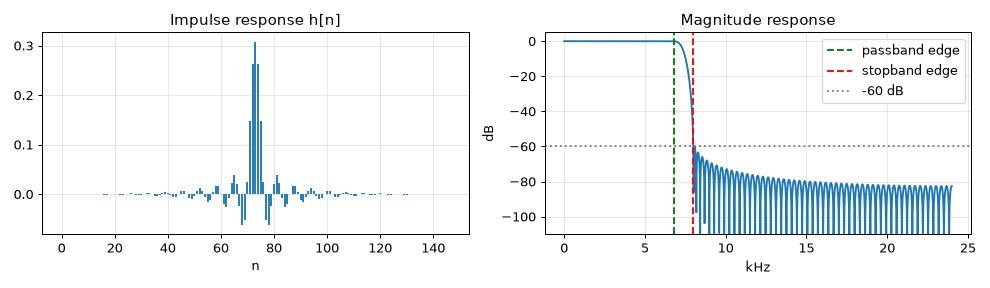

In [ ]:
# low pass
h = dsp.kaiser_lowpass(cfg.aa_passband_hz, cfg.aa_stopband_hz, cfg.aa_ripple, fs_in)
A = -20 * np.log10(cfg.aa_ripple)
print(f"A = {A:.0f} dB, beta = {0.1102 * (A - 8.7):.2f}, M = {len(h) - 1}  ->  {len(h)} taps, symmetric: {np.allclose(h, h[::-1])}")

f, H = signal.freqz(h, worN=8192, fs=fs_in)
fig, ax = plt.subplots(1, 2)
ax[0].stem(np.arange(len(h)), h, markerfmt=" ", basefmt=" ")
ax[0].set(title="Impulse response h[n]", xlabel="n")
ax[1].plot(f / 1000, 20 * np.log10(np.abs(H) + 1e-12))
ax[1].axvline(cfg.aa_passband_hz / 1000, color="g", ls="--", label="passband edge")
ax[1].axvline(cfg.aa_stopband_hz / 1000, color="r", ls="--", label="stopband edge")
ax[1].axhline(-A, color="gray", ls=":", label=f"-{A:.0f} dB")
ax[1].set(title="Magnitude response", xlabel="kHz", ylabel="dB", ylim=(-110, 5)); ax[1].legend()
plt.tight_layout()

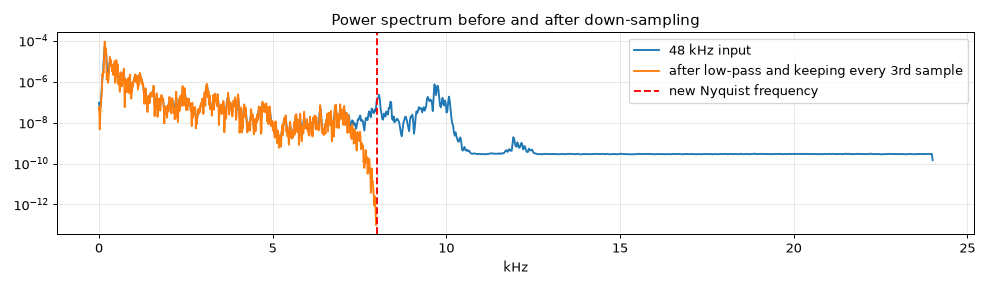

In [3]:
dec = dsp.Decimator(fs_in, cfg.target_sr, h=h)        # stateful: can be fed block by block
x16 = dec.process(x48)
fs = cfg.target_sr

fig, ax = plt.subplots()
for sig, rate, name in ((x48, fs_in, "48 kHz input"), (x16, fs, "after low-pass and keeping every 3rd sample")):
    f, P = signal.welch(sig, rate, nperseg=2048)
    ax.semilogy(f / 1000, P, label=name)
ax.axvline(fs / 2000, color="r", ls="--", label="new Nyquist frequency")
ax.set(title="Power spectrum before and after down-sampling", xlabel="kHz"); ax.legend(); plt.tight_layout()

50 Hz reduced by 52 dB, the 12 harmonics by 18 dB on average; weights were updated on 14 % of the samples


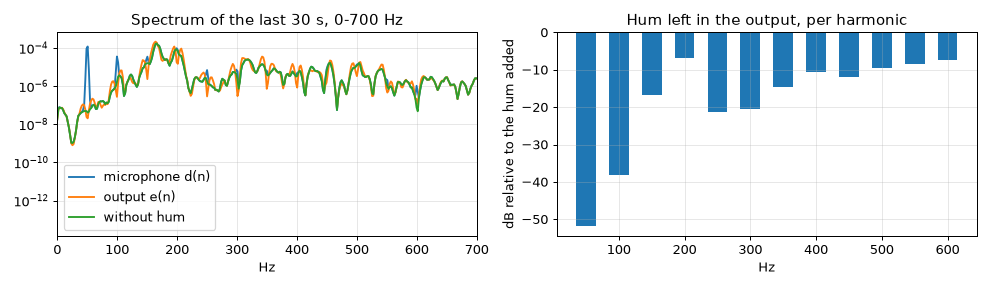

In [4]:
n = 60 * fs
clean = x16[:n]
t = np.arange(n) / fs
rng = np.random.default_rng(1)
phase = rng.uniform(0, 2 * np.pi, 12)
hum = sum(np.sin(2 * np.pi * 50 * k * t + phase[k - 1]) / k for k in range(1, 13))
speech_power = np.mean(np.concatenate([clean[int(s * fs):int(e * fs)] for s, e, _ in ref if e < 60]) ** 2)
hum *= np.sqrt(speech_power / np.mean(hum ** 2) / 10)             # 10 dB below the speech

anc = dsp.AdaptiveNoiseCanceller(cfg.anc_taps, int(cfg.anc_delay_s * fs), cfg.anc_mu, fs, cfg.anc_gate_db)
e = anc.process(clean + hum)

# how much of each hum harmonic is left in the output (last 30 s): project the error onto that tone
last = slice(30 * fs, n)
def tone_level(x, f):
    c = np.exp(-2j * np.pi * f * t[last])
    return np.abs(np.mean(x[last] * c))
left = [20 * np.log10(tone_level(e - clean, 50 * k) / tone_level(hum, 50 * k)) for k in range(1, 13)]

fig, ax = plt.subplots(1, 2)
for sig, name in ((clean + hum, "microphone d(n)"), (e, "output e(n)"), (clean, "without hum")):
    f, P = signal.welch(sig[last], fs, nperseg=8192)
    ax[0].semilogy(f, P, label=name)
ax[0].set(xlim=(0, 700), title="Spectrum of the last 30 s, 0-700 Hz", xlabel="Hz"); ax[0].legend()
ax[1].bar(50 * np.arange(1, 13), left, width=30)
ax[1].set(title="Hum left in the output, per harmonic", xlabel="Hz", ylabel="dB relative to the hum added")
plt.tight_layout()
print(f"50 Hz reduced by {-left[0]:.0f} dB, the 12 harmonics by {-np.mean(left):.0f} dB on average; weights were updated on {anc.adapting / n * 100:.0f} % of the samples")

## 3. Pre-emphasis and Hamming framing

*Course: CH04-01 FIR vs. IIR (a 2-tap FIR with one zero), CH04-03 windows.*

Speech has less energy at high frequencies. y[n] = x[n] − 0.97 x[n−1] lifts them so the formants stand out.
The signal is then cut into 32 ms frames every 10 ms, because speech is roughly stationary over that time,
and each frame is multiplied by a Hamming window to reduce spectral leakage.

10792 frames of 512 samples


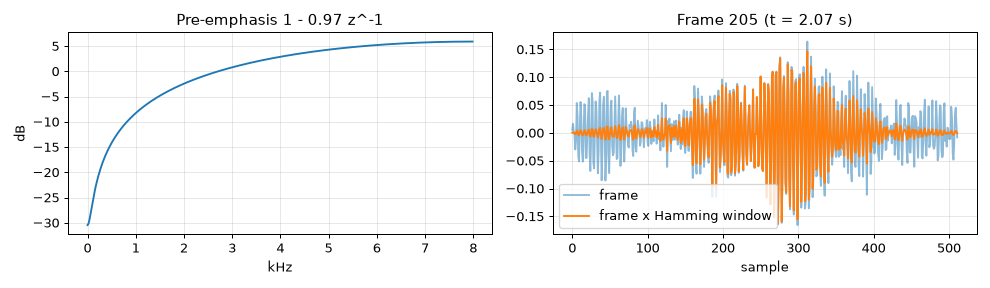

In [5]:
pre = dsp.PreEmphasis(cfg.preemph).process(x16)
frames = dsp.frame_signal(pre, cfg.win_len, cfg.hop_len) * dsp.hamming(cfg.win_len)
frame_t = (np.arange(len(frames)) * cfg.hop_len + cfg.win_len / 2) / fs
k = int(np.argmax(np.sum(frames[100:400] ** 2, axis=1))) + 100       # a loud (voiced) frame in the first turn

f, H = signal.freqz([1, -cfg.preemph], worN=512, fs=fs)
fig, ax = plt.subplots(1, 2)
ax[0].plot(f / 1000, 20 * np.log10(np.abs(H)))
ax[0].set(title="Pre-emphasis 1 - 0.97 z^-1", xlabel="kHz", ylabel="dB")
ax[1].plot(dsp.frame_signal(pre, cfg.win_len, cfg.hop_len)[k], alpha=0.5, label="frame")
ax[1].plot(frames[k], label="frame x Hamming window")
ax[1].set(title=f"Frame {k} (t = {frame_t[k]:.2f} s)", xlabel="sample"); ax[1].legend()
plt.tight_layout()
print(f"{len(frames)} frames of {cfg.win_len} samples")

## 4. AR model of a frame (linear prediction)

*Course: CH05-01 AR model and linear prediction, CH05-02 normal equation.*

A frame is modelled as x[n] = a₁x[n−1] + … + aₚx[n−p] + w[n] with p = 16. The coefficients come from the
normal equations R a = r, where r[k] is the autocorrelation of the frame and R is the Toeplitz matrix of
r[0..p−1]. 1/|A(e^jω)|² is then a smooth envelope of the frame's spectrum: the shape of the vocal tract.

a = [-0.8  -1.75 -1.78 -2.38 -1.72 -2.26 -1.46 -1.75 -0.9  -0.93 -0.16 -0.28
  0.23 -0.06  0.13 -0.02]


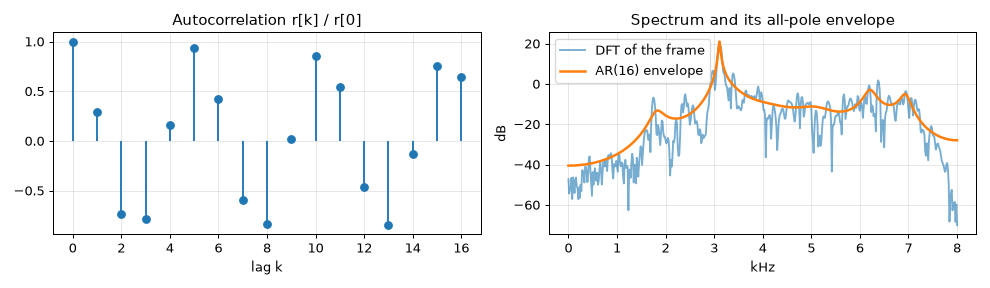

In [6]:
from diarize.ar import prediction_error_filter

r = dsp.autocorr_lags(frames[k:k + 1], cfg.ar_order)[0]
Afilt = prediction_error_filter(r / r[0])                     # [1, -a1, ..., -ap]
print("a =", np.round(-Afilt[1:], 2))

spec = np.abs(np.fft.rfft(frames[k], 1024)) ** 2
f = np.fft.rfftfreq(1024, 1 / fs)
_, Henv = signal.freqz([1.0], Afilt, worN=f, fs=fs)
env = np.abs(Henv) ** 2
env *= np.mean(spec) / np.mean(env)
fig, ax = plt.subplots(1, 2)
ax[0].stem(np.arange(len(r)), r / r[0], basefmt=" ")
ax[0].set(title="Autocorrelation r[k] / r[0]", xlabel="lag k")
ax[1].plot(f / 1000, 10 * np.log10(spec + 1e-12), alpha=0.6, label="DFT of the frame")
ax[1].plot(f / 1000, 10 * np.log10(env), lw=2, label="AR(16) envelope")
ax[1].set(title="Spectrum and its all-pole envelope", xlabel="kHz", ylabel="dB"); ax[1].legend()
plt.tight_layout()

## 5. Pitch: Butterworth band-pass, centre clipping, autocorrelation

*Course: CH04-02 IIR design (Butterworth, bilinear transformation), CH04-01 cascade form, CH04-03 clippers.*

A 4th-order Butterworth band-pass (60–900 Hz, cascade of second-order sections) keeps the range where the
pitch lives. Centre clipping, a non-linear block, removes the formant ripple and keeps the pitch pulses. A
voiced frame is periodic, so its autocorrelation peaks at the pitch period T, and F0 = fs / T.

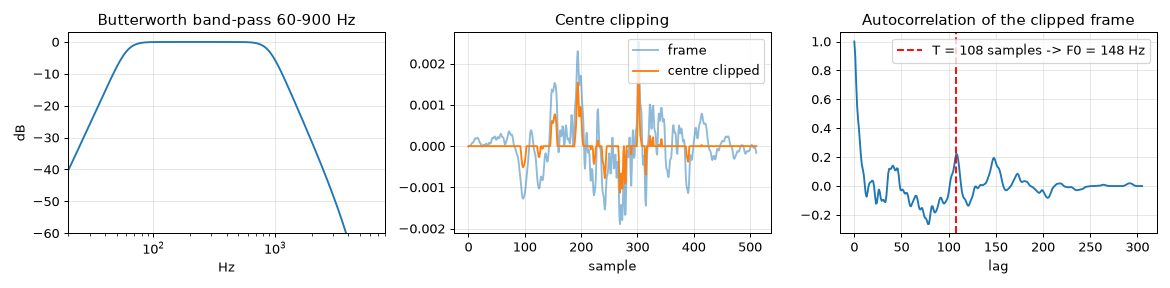

In [7]:
bp = dsp.Butterworth(cfg.bp_order, cfg.pitch_band, fs, "bandpass")
f, H = signal.sosfreqz(bp.sos, worN=4096, fs=fs)
pitch_frames = dsp.frame_signal(bp.process(x16), cfg.win_len, cfg.hop_len)

fr = pitch_frames[k] * dsp.hamming(cfg.win_len)
clipped = dsp.center_clip(fr[None, :], cfg.clip_ratio)[0]
ac = dsp.autocorrelation(clipped[None, :])[0]
lo, hi = int(fs / cfg.f0_max), int(fs / cfg.f0_min)
peak = lo + int(np.argmax(ac[lo:hi]))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].semilogx(f, 20 * np.log10(np.abs(H) + 1e-9)); ax[0].set(title="Butterworth band-pass 60-900 Hz", xlabel="Hz", ylabel="dB", ylim=(-60, 3), xlim=(20, 8000))
ax[1].plot(fr, alpha=0.5, label="frame"); ax[1].plot(clipped, label="centre clipped"); ax[1].set(title="Centre clipping", xlabel="sample"); ax[1].legend()
ax[2].plot(ac[:hi + 40] / ac[0]); ax[2].axvline(peak, color="r", ls="--", label=f"T = {peak} samples -> F0 = {fs / peak:.0f} Hz")
ax[2].set(title="Autocorrelation of the clipped frame", xlabel="lag"); ax[2].legend()
plt.tight_layout()

Daniel: median F0 117 Hz
Samantha: median F0 173 Hz


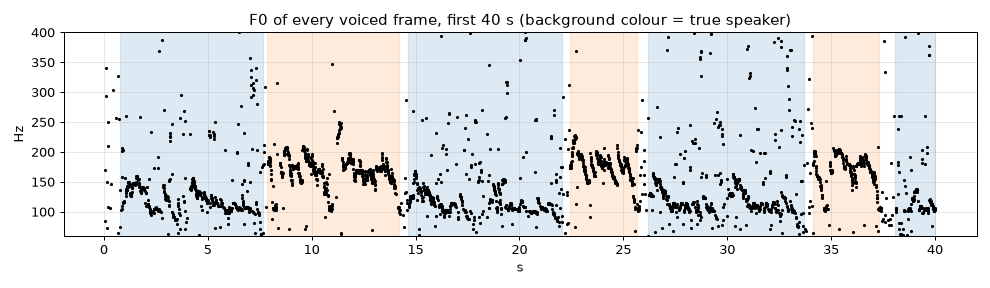

In [8]:
f0, voicing = dsp.pitch_autocorr(pitch_frames, fs, cfg.f0_min, cfg.f0_max, cfg.clip_ratio, cfg.voicing_thr)
colors = dict(zip(speakers, ("tab:blue", "tab:orange", "tab:green", "tab:purple")))
fig, ax = plt.subplots()
for s, e, lab in ref:
    if s < 40: ax.axvspan(s, min(e, 40), color=colors[lab], alpha=0.15)
v = (f0 > 0) & (frame_t[:len(f0)] < 40)
ax.plot(frame_t[:len(f0)][v], f0[v], ".", ms=3, color="k")
ax.set(title="F0 of every voiced frame, first 40 s (background colour = true speaker)", xlabel="s", ylabel="Hz", ylim=(60, 400))
plt.tight_layout()
for lab in speakers:
    m = np.zeros(len(f0), bool)
    for s, e, l in ref:
        if l == lab: m |= (frame_t[:len(f0)] >= s) & (frame_t[:len(f0)] < e)
    print(f"{lab}: median F0 {np.median(f0[m & (f0 > 0)]):.0f} Hz")

## 6. Energy VAD and median filter

*Course: CH04-03 median filters (non-linear filtering).*

A frame is "loud" when its energy is more than 10 dB above a noise floor that follows the energy down
quickly and up slowly. That decision flickers, so it goes through a 5-frame median filter, which removes
isolated clicks and fills one-frame dropouts without moving the edges.

raw decision changes 164 times, after the median filter 134 times


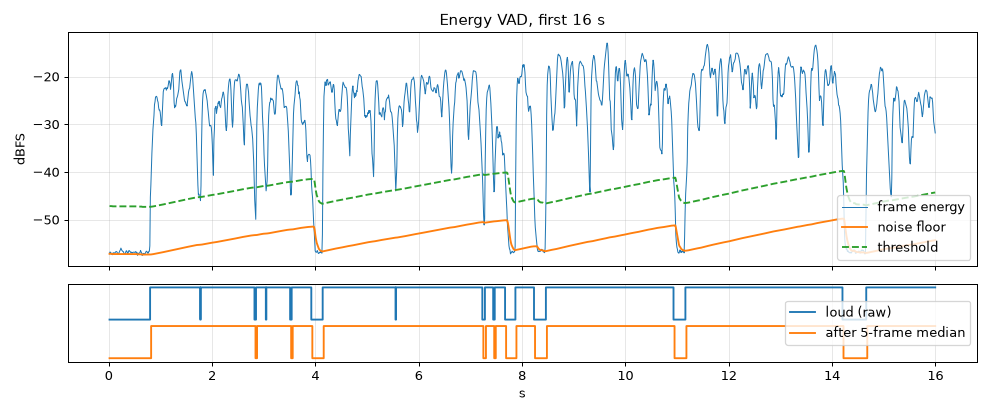

In [9]:
from diarize.vad import EnergyVAD

hp = dsp.Butterworth(cfg.bp_order, cfg.audio_hp, fs, "highpass")
audio = hp.process(x16)                                       # this branch is also the audio written to the output files
energy_db = 10 * np.log10(np.mean(dsp.frame_signal(audio, cfg.win_len, cfg.hop_len) ** 2, axis=1) + 1e-12)

vad = EnergyVAD(cfg)
speech, floor = [], []
for e_db in energy_db:                                        # one frame at a time, to record the noise floor
    speech.append(vad.process(np.array([e_db]))[0]); floor.append(vad.noise_db)
speech, floor = np.array(speech), np.array(floor)
loud = energy_db > np.maximum(floor + cfg.vad_margin_db, cfg.vad_abs_floor_db)

sel = frame_t[:len(energy_db)] < 16
fig, ax = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, height_ratios=[3, 1])
ax[0].plot(frame_t[:len(energy_db)][sel], energy_db[sel], lw=0.8, label="frame energy")
ax[0].plot(frame_t[:len(energy_db)][sel], floor[sel], label="noise floor")
ax[0].plot(frame_t[:len(energy_db)][sel], floor[sel] + cfg.vad_margin_db, ls="--", label="threshold")
ax[0].set(ylabel="dBFS", title="Energy VAD, first 16 s"); ax[0].legend(loc="lower right")
ax[1].step(frame_t[:len(energy_db)][sel], loud[sel] + 1.2, where="mid", label="loud (raw)")
ax[1].step(frame_t[:len(energy_db)][sel], speech[sel], where="mid", label="after 5-frame median")
ax[1].set(yticks=[], xlabel="s"); ax[1].legend(loc="center right")
plt.tight_layout()
print(f"raw decision changes {np.sum(np.diff(loud.astype(int)) != 0)} times, after the median filter {np.sum(np.diff(speech.astype(int)) != 0)} times")

## 7. Speaker model: a dictionary per speaker, learned with K-SVD, used with OMP

*Course: CH06-01 sparse coding, OMP, K-SVD.*

Each frame is described by the log spectral envelope of its AR model at 32 frequencies. One person produces
many different envelopes (vowels, consonants), so a speaker is modelled by a dictionary D of 16 envelope
"atoms" learned from that speaker's own frames:

- **K-SVD** alternates sparse coding of all frames and updating one atom at a time as the best rank-1 fit
  (SVD) of the error left for the frames that use it.
- **OMP** codes a frame x as x ≈ Dᵀα with at most one non-zero coefficient.
- The share of energy that cannot be represented, ‖x − Dᵀα‖² / ‖x‖², says how well the frame fits the speaker.

Below, a dictionary is learned for each of the two speakers from the first half of their speech, and the
second half is coded with both dictionaries.

share of energy NOT represented (rows: whose speech, columns: whose dictionary)
              Daniel  Samantha
    Daniel     0.112     0.351
  Samantha     0.384     0.134
decision threshold in the pipeline: 0.21


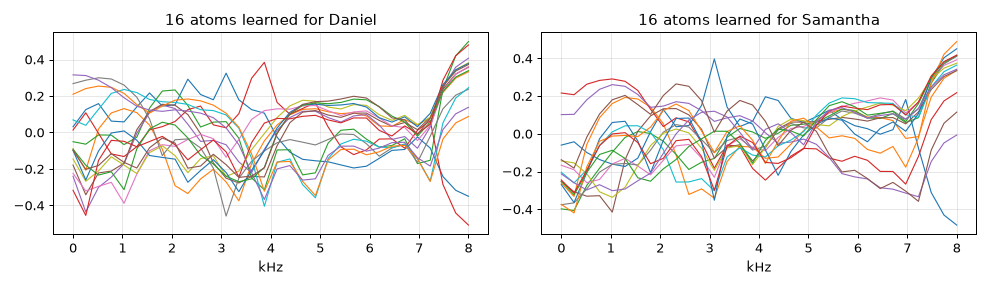

In [10]:
from diarize.frontend import FrontEnd
from diarize.sparse import ksvd, residual_ratio

fe = FrontEnd(cfg, fs_in)                                     # the real streaming front-end, fed 50 ms at a time
parts = [fe.process(x48[i:i + 2400]) for i in range(0, len(x48), 2400)]
feat = np.concatenate([p.feat for p in parts]); f0_fe = np.concatenate([p.f0 for p in parts])
is_speech = EnergyVAD(cfg).process(np.concatenate([p.energy_db for p in parts]))
X = feat[:, cfg.ar_order:]                                    # the 32-point envelope part of the feature vector
tt = (np.arange(len(X)) * cfg.hop_len + cfg.win_len / 2) / fs

frames_of = {}
for lab in speakers:
    m = np.zeros(len(X), bool)
    for s, e, l in ref:
        if l == lab: m |= (tt >= s + 0.1) & (tt < e - 0.1)
    frames_of[lab] = X[m & is_speech]
D = {lab: ksvd(Xs[:len(Xs) // 2], cfg.dict_atoms, cfg.dict_sparsity) for lab, Xs in frames_of.items()}

fig, ax = plt.subplots(1, 2)
for a, lab in zip(ax, speakers):
    a.plot(np.linspace(0, 8, cfg.dict_nfreq), D[lab].T, lw=0.9)
    a.set(title=f"16 atoms learned for {lab}", xlabel="kHz")
plt.tight_layout()

print("share of energy NOT represented (rows: whose speech, columns: whose dictionary)")
print(" " * 10 + "".join(f"{lab:>10}" for lab in speakers))
for lab, Xs in frames_of.items():
    print(f"{lab:>10}" + "".join(f"{residual_ratio(D[other], Xs[len(Xs) // 2:], cfg.dict_sparsity):10.3f}" for other in speakers))
print(f"decision threshold in the pipeline: {cfg.dict_thr}")

## 8. Finding a speaker change inside continuous speech

Speakers sometimes follow each other with no pause. Two adjacent 1 s windows are compared: a small dictionary
(8 atoms) is learned on each, and each window is coded with the other's dictionary. For the same speaker the
residual is about as small as with its own dictionary; after a change it is clearly larger. The jump of the
mean log-F0 is added. The pipeline cuts at a peak above the threshold.

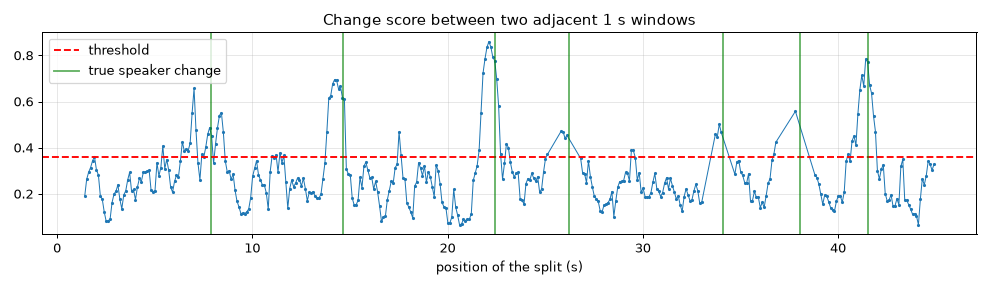

In [11]:
from diarize.sparse import change_score

W, t_end = 100, 45.0
ts, score = [], []
for split in range(W, int(t_end * 100), 10):
    L, R = slice(split - W, split), slice(split, split + W)
    mL, mR = is_speech[L], is_speech[R]
    if mL.sum() < cfg.bic_min_speech or mR.sum() < cfg.bic_min_speech:
        continue
    ts.append(tt[split])
    score.append(change_score(X[L][mL], f0_fe[L][mL], X[R][mR], f0_fe[R][mR], cfg.dict_change_atoms, cfg.dict_change_pitch))

fig, ax = plt.subplots()
ax.plot(ts, score, ".-", ms=3, lw=0.8)
ax.axhline(cfg.dict_change_thr, color="r", ls="--", label="threshold")
for i, (s, e, lab) in enumerate(ref[1:]):
    if s < t_end: ax.axvline(s, color="g", alpha=0.6, label="true speaker change" if i == 0 else None)
ax.set(title="Change score between two adjacent 1 s windows", xlabel="position of the split (s)"); ax.legend()
plt.tight_layout()

## 9. The whole pipeline, streaming

`StreamingDiarizer` runs all of the above block by block: 50 ms of audio in, finished speaker segments out.
A segment is closed at a pause of 0.3 s or at a detected speaker change, labelled by the online clustering
(join the speaker whose dictionary leaves the smallest residual, or open a new speaker), and cleaned.

33 segments, 2 speakers found (true: 2)
DER 0.7 %  (missed 0.7, false alarm 0.0, confusion 0.0)
speaker F1 98.6 %, delay: mean 0.78 s, max 1.36 s
processed 108 s of audio in 14.9 s (7.2x faster than real time)


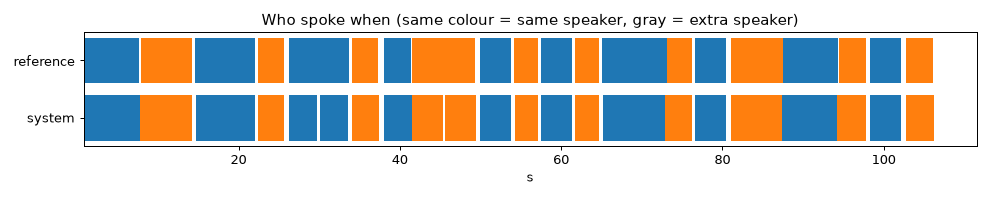

In [12]:
import time
from diarize.pipeline import StreamingDiarizer
from diarize.evaluate import der, speaker_f1

d = StreamingDiarizer(cfg, input_sr=fs_in)
t0 = time.perf_counter()
for i in range(0, len(x48), 2400):                            # 50 ms blocks, as from a microphone
    d.push(x48[i:i + 2400])
d.flush()
wall = time.perf_counter() - t0

hyp = [(s.start, s.end, s.label) for s in d.segments]
res, f1 = der(ref, hyp, 0.25), speaker_f1(ref, hyp)
print(f"{len(d.segments)} segments, {len({s.speaker for s in d.segments})} speakers found (true: {len(speakers)})")
print(f"DER {res['DER'] * 100:.1f} %  (missed {res['missed'] * 100:.1f}, false alarm {res['false_alarm'] * 100:.1f}, confusion {res['confusion'] * 100:.1f})")
print(f"speaker F1 {f1['macro_f1'] * 100:.1f} %, delay: mean {np.mean([s.latency_s for s in d.segments]):.2f} s, max {max(s.latency_s for s in d.segments):.2f} s")
print(f"processed {len(x48) / fs_in:.0f} s of audio in {wall:.1f} s ({len(x48) / fs_in / wall:.1f}x faster than real time)")

mapping = f1["mapping"]                                       # system label -> the true speaker it overlaps most
fig, ax = plt.subplots(figsize=(11, 2.2))
for s, e, lab in ref:
    ax.barh(1, e - s, left=s, color=colors[lab], edgecolor="none")
for s, e, lab in hyp:
    ax.barh(0, e - s, left=s, color=colors.get(mapping.get(lab), "gray"), edgecolor="none")
ax.set(yticks=[0, 1], yticklabels=["system", "reference"], xlabel="s", title="Who spoke when (same colour = same speaker, gray = extra speaker)")
ax.grid(False); plt.tight_layout()

## 10. Cleaning a segment with a Wiener filter

*Course: CH05-02 Wiener filter, signal denoising.*

Before a segment is written to a file, each frequency is scaled by the Wiener gain H = S / (S + N). The noise
power N comes from the most recent silence, and the speech power S is estimated as (power of the frame) − N.

level of the 10 quietest frames: -56.9 dB -> -66.0 dB


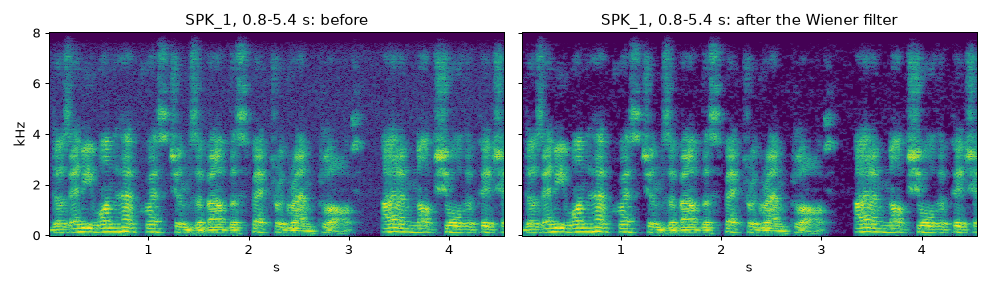

In [13]:
from diarize.cleaner import denoise, noise_psd

seg = max(d.segments, key=lambda s: s.end - s.start)
raw = audio[int(seg.start * fs):int(seg.end * fs)]
noise = audio[int(0.1 * fs):int(0.7 * fs)]                    # the silence before the first turn
cleaned = denoise(raw, fs, noise_psd(noise, fs), "wiener", floor=cfg.clean_floor)

fig, ax = plt.subplots(1, 2, sharey=True)
for a, sig, name in ((ax[0], raw, "before"), (ax[1], cleaned, "after the Wiener filter")):
    f, t_, Sxx = signal.spectrogram(sig, fs, nperseg=512, noverlap=384)
    a.pcolormesh(t_, f / 1000, 10 * np.log10(Sxx + 1e-12), vmin=-110, vmax=-40, shading="auto")
    a.set(title=f"{seg.label}, {seg.start:.1f}-{seg.end:.1f} s: {name}", xlabel="s"); a.grid(False)
ax[0].set(ylabel="kHz"); plt.tight_layout()

quiet = np.sort(dsp.frame_signal(raw, 512, 160).var(axis=1))[:10].mean(), np.sort(dsp.frame_signal(cleaned, 512, 160).var(axis=1))[:10].mean()
print(f"level of the 10 quietest frames: {10 * np.log10(quiet[0]):.1f} dB -> {10 * np.log10(quiet[1]):.1f} dB")